# Exerciții de Regularizare și Coborârea Gradientului
![UnderOverFit.png](../assets/UnderOverFit.png)

# Obiectivele învățării

- Explicarea funcțiilor de cost, regularizarea, selectarea caracteristicilor și hiperparametrii
- Rezumarea algoritmilor de optimizare statistică complexă, cum ar fi coborârea gradientului și aplicarea sa la regresia liniară

## Introducere

Vom începe cu un scurt tutorial despre regresie, caracteristici polinomiale și regularizare, bazat pe un set de date foarte simplu, rar, care conține o coloană de date `x` și date zgomotoase asociate `y`. Fișierul de date se numește `X_Y_Sinusoid_Data.csv`.

In [1]:
# Importuri pentru manipularea datelor si vizualizare
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calea catre date - compatibil indiferent din ce folder este rulat notebook-ul
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

# Incercam accelerarea Intel Scikit-learn daca este disponibila
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    pass

# Importuri din scikit-learn
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Întrebare 1

* Importați datele. 

* De asemenea, generați aproximativ 100 de puncte de date x egal distanțate pe intervalul 0-1. Folosind aceste puncte, calculați datele y care reprezintă „adevărul de bază” (funcția reală) din ecuația: $y = \sin(2\pi x)$

* Reprezentați grafic datele rarefiate (`x` vs `y`) și datele calculate („reale”).

In [2]:
# Incarcam datele din fisierul CSV
filepath = os.sep.join(data_path + ['X_Y_Sinusoid_Data.csv'])
if not os.path.exists(filepath):
    filepath = 'X_Y_Sinusoid_Data.csv'
data = pd.read_csv(filepath)

# Generam 100 de puncte egal distantate pe intervalul [0, 1]
X_real = np.linspace(0, 1.0, 100)

# Calculam y conform functiei reale: sin(2 * pi * x)
Y_real = np.sin(2 * np.pi * X_real)

# Afisam primele randuri din setul de date
print("Primele randuri din datele sinusoidale:")
print(data.head())

Primele randuri din datele sinusoidale:
          x         y
0  0.038571  0.066391
1  0.166776  1.027483
2  0.183153  1.245302
3  0.187359  1.004781
4  0.243116  1.264121


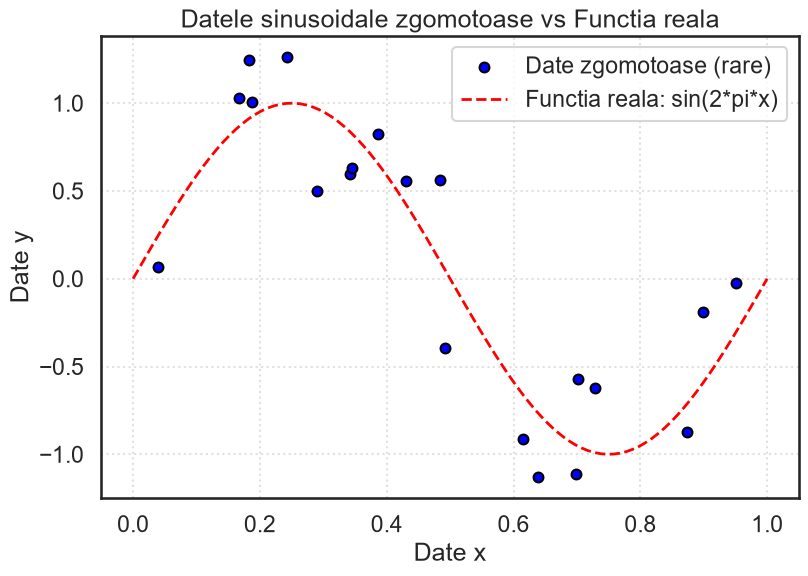

In [3]:
# Configurare stil grafice
sns.set_style('white')
sns.set_context('talk')
sns.set_palette('dark')

# Reprezentam grafic datele zgomotoase si functia reala
plt.figure(figsize=(9, 6))
plt.scatter(data['x'], data['y'], color='blue', label='Date zgomotoase (rare)', s=50, edgecolors='k')
plt.plot(X_real, Y_real, color='red', linestyle='--', linewidth=2, label='Functia reala: sin(2*pi*x)')

plt.xlabel('Date x')
plt.ylabel('Date y')
plt.title('Datele sinusoidale zgomotoase vs Functia reala')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Întrebarea 2

* Folosind clasa `PolynomialFeatures` din biblioteca de preprocesare Scikit-learn, creați caracteristici polinomiale de ordinul 20.
* Adaptați aceste date folosind regresia liniară. 
* Reprezentați grafic valoarea prezisă rezultată în comparație cu datele calculate.

Rețineți că `PolynomialFeatures` necesită fie un cadru de date (cu o coloană, nu o serie), fie o matrice 2D de dimensiune (`X`, 1), unde `X` este lungimea.

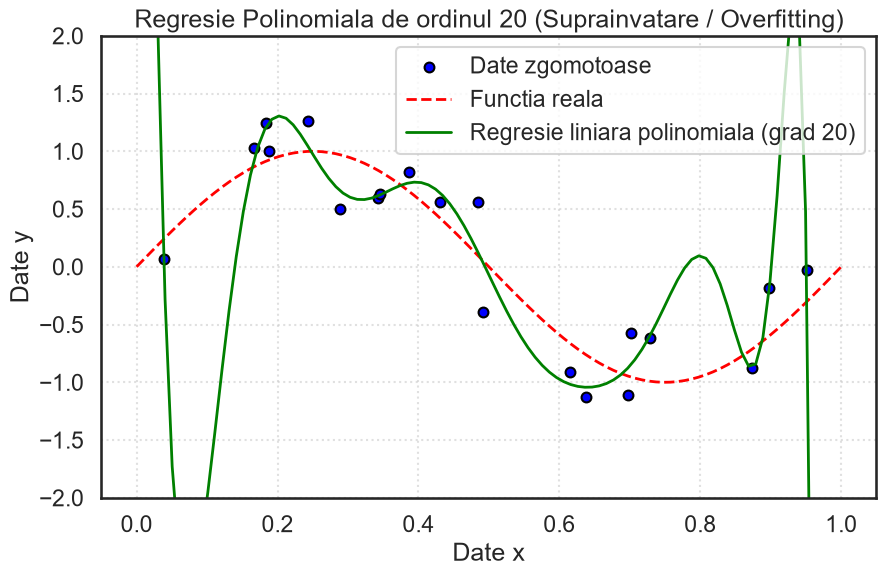

In [4]:
# Cream caracteristici polinomiale de gradul 20
degree = 20
pf = PolynomialFeatures(degree=degree, include_bias=False)

# Transformam variabila x in caracteristici polinomiale (matrice 2D)
X_poly = pf.fit_transform(data[['x']])

# Instantiem si antrenam modelul de regresie liniara simpla
lr = LinearRegression()
lr.fit(X_poly, data['y'])

# Generam predictii pe cele 100 de puncte ale functiei reale
X_real_poly = pf.transform(X_real.reshape(-1, 1))
Y_real_pred = lr.predict(X_real_poly)

# Reprezentare grafica comparativa
plt.figure(figsize=(10, 6))
plt.scatter(data['x'], data['y'], color='blue', label='Date zgomotoase', s=50, edgecolors='k')
plt.plot(X_real, Y_real, color='red', linestyle='--', linewidth=2, label='Functia reala')
plt.plot(X_real, Y_real_pred, color='green', linewidth=2, label='Regresie liniara polinomiala (grad 20)')

# Limitam axa y pentru a evidentia oscilatiile extreme cauzate de overfitting
plt.ylim(-2, 2)
plt.xlabel('Date x')
plt.ylabel('Date y')
plt.title('Regresie Polinomiala de ordinul 20 (Suprainvatare / Overfitting)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Întrebare 3

* Efectuați regresia pe baza datelor cu caracteristici polinomiale utilizând regresia Ridge ($\alpha$=0,001) și regresia Lasso ($\alpha$=0,0001). 
* Reprezentați grafic rezultatele, așa cum s-a făcut la întrebarea 1. 
* De asemenea, reprezentați grafic magnitudinea coeficienților obținuți din aceste regresii și comparați-i cu cei obținuți din regresia liniară din întrebarea anterioară. Coeficienții regresiei liniare vor necesita probabil un grafic separat (sau propria axă y) din cauza magnitudinii lor mari. 

Ce vă spune magnitudinea comparativ mare a datelor cu privire la rolul regularizării?

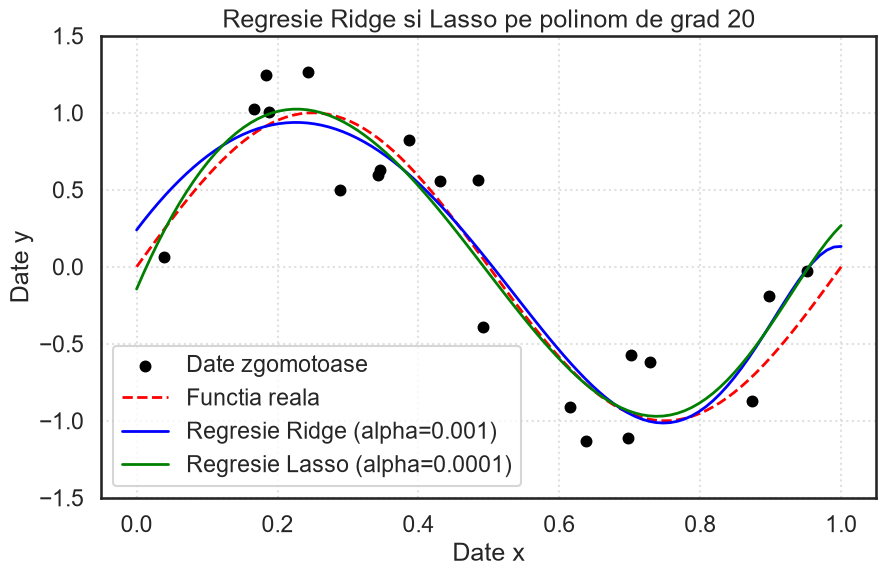

In [5]:
# Dezactivam avertismentele sklearn legate de convergenta daca e cazul
warnings.filterwarnings('ignore', module='sklearn')

# Regresie Ridge (regularizare L2)
rr = Ridge(alpha=0.001)
rr.fit(X_poly, data['y'])
Y_ridge_pred = rr.predict(X_real_poly)

# Regresie Lasso (regularizare L1)
lassor = Lasso(alpha=0.0001, max_iter=100000)
lassor.fit(X_poly, data['y'])
Y_lasso_pred = lassor.predict(X_real_poly)

# Reprezentare grafica a predictiilor modelelor regularizate
plt.figure(figsize=(10, 6))
plt.scatter(data['x'], data['y'], color='black', label='Date zgomotoase', s=50, edgecolors='k')
plt.plot(X_real, Y_real, color='red', linestyle='--', linewidth=2, label='Functia reala')
plt.plot(X_real, Y_ridge_pred, color='blue', linewidth=2, label='Regresie Ridge (alpha=0.001)')
plt.plot(X_real, Y_lasso_pred, color='green', linewidth=2, label='Regresie Lasso (alpha=0.0001)')

plt.ylim(-1.5, 1.5)
plt.xlabel('Date x')
plt.ylabel('Date y')
plt.title('Regresie Ridge si Lasso pe polinom de grad 20')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [6]:
# Analizam valoarea absoluta a coeficientilor pentru fiecare model
coefficients = pd.DataFrame()
coefficients['linear regression'] = lr.coef_.ravel()
coefficients['ridge regression'] = rr.coef_.ravel()
coefficients['lasso regression'] = lassor.coef_.ravel()
coefficients = coefficients.abs()

# Diferenta uriasa de scara intre regresia neregularizata si cea regularizata
coefficients.describe()

,linear regression,ridge regression,lasso regression
count,20.000000,20.000000,20.000000
mean,122050.272218,2.277867,2.798440
std,79670.198610,2.931594,6.920062
min,743.468485,0.123363,0.000000
25%,62606.496596,0.508969,0.000000
50%,116633.276082,1.100772,0.000000
75%,163391.240879,3.180162,0.275864
max,307899.873320,12.429635,25.359652


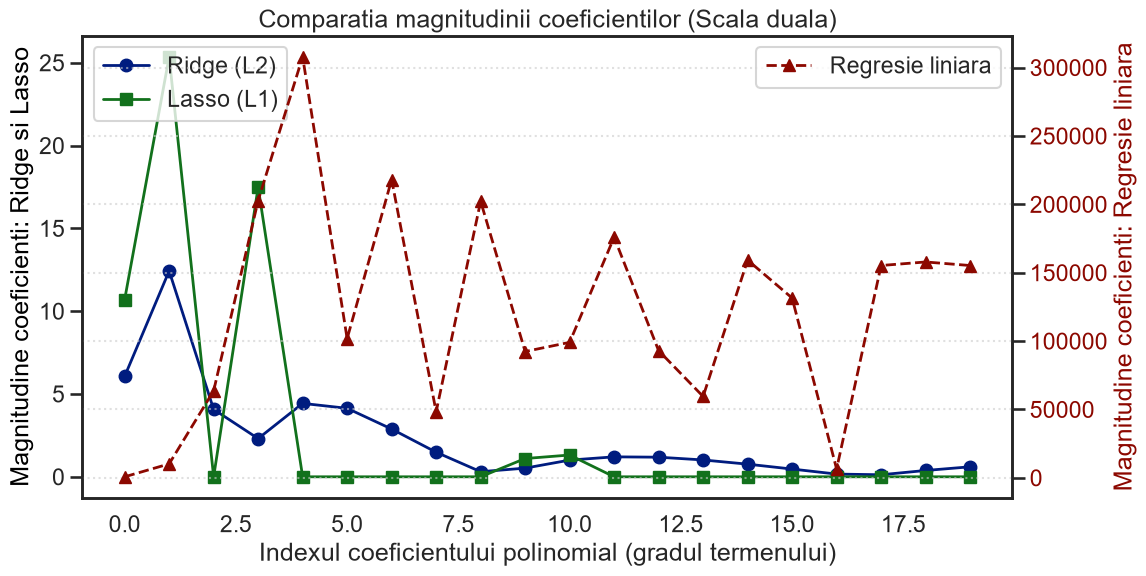

In [7]:
# Reprezentam grafic magnitudinea coeficientilor folosind o axa y duala
colors = sns.color_palette()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Axa stanga: Coeficientii modelelor regularizate Ridge si Lasso (valori mici)
ax1.plot(coefficients['ridge regression'], color=colors[0], marker='o', linewidth=2, label='Ridge (L2)')
ax1.plot(coefficients['lasso regression'], color=colors[2], marker='s', linewidth=2, label='Lasso (L1)')
ax1.set_xlabel('Indexul coeficientului polinomial (gradul termenului)')
ax1.set_ylabel('Magnitudine coeficienti: Ridge si Lasso', color='black')
ax1.tick_params(axis='y')

# Axa dreapta: Coeficientii regresiei liniare clasice fara regularizare (valori uriase)
ax2 = ax1.twinx()
ax2.plot(coefficients['linear regression'], color=colors[3], marker='^', linestyle='--', linewidth=2, label='Regresie liniara')
ax2.set_ylabel('Magnitudine coeficienti: Regresie liniara', color=colors[3])
ax2.tick_params(axis='y', labelcolor=colors[3])

plt.title('Comparatia magnitudinii coeficientilor (Scala duala)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Concluzie privind rolul regularizării:

Magnitudinea extrem de mare a coeficienților din regresia liniară simplă (depășind $10^5$) demonstrează o problemă severă de **supra-ajustare (overfitting)**: modelul compensează zgomotul din date prin oscilații extreme cu ponderi uriașe, pozitive și negative.

**Regularizarea** rezolvă această problemă prin penalizarea coeficienților mari:
- **Ridge (penalizare $L_2$)**: micșorează uniform magnitudinea ponderilor spre zero, netezind curba și prevenind oscilațiile sălbatice.
- **Lasso (penalizare $L_1$)**: forțează o parte din coeficienți să devină exact zero, realizând concomitent regularizare și selecție automată de caracteristici (sparsity).

## Întrebarea 4

Pentru întrebările rămase, vom lucra cu [setul de date](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) din lecția trecută, care se bazează pe prețurile locuințelor din Ames, Iowa. Există un număr mare de caracteristici - a se vedea exercițiile din săptămâna a treia pentru o discuție despre aceste caracteristici.

Pentru a începe:

* Importați datele cu Pandas, eliminați orice valori nule și o codificare one-hot a categoriilor. Pot fi utilizate fie codificatoarele de caracteristici Scikit-learn, fie metoda Pandas `get_dummies`.
* Împărțiți datele în seturi de instruire și de testare. 
* Transformarea logaritmică a caracteristicilor distorsionate. 
* Se poate încerca scalarea, deși poate fi interesant să se vadă cât de bine funcționează regularizarea fără scalarea caracteristicilor.

In [8]:
# Incarcam datele din setul Ames Housing Sales
filepath = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
if not os.path.exists(filepath):
    filepath = 'Ames_Housing_Sales.csv'
data = pd.read_csv(filepath, sep=',')

# Tratarea valorilor lipsa din coloanele categorice (inlocuire cu categoria explicita 'None')
cat_cols = data.select_dtypes(include=['object', 'string', 'category']).columns
data[cat_cols] = data[cat_cols].fillna('None')

# Ne asiguram ca nu mai avem nicio valoare lipsa in intreg dataframe-ul
data = data.dropna()
print("Dimensiunea setului de date dupa tratarea valorilor nule:", data.shape)

Dimensiunea setului de date dupa tratarea valorilor nule: (1379, 80)


Creați o listă de date categoriale și codificați one-hot. Pandas one-hot encoder (`get_dummies`) funcționează bine cu date care sunt definite ca fiind categoriale.

In [9]:
# Codificam one-hot toate variabilele categorice folosind get_dummies
data_encoded = pd.get_dummies(data, drop_first=True)
print("Dimensiunea datelor dupa codificarea One-Hot:", data_encoded.shape)

Dimensiunea datelor dupa codificarea One-Hot: (1379, 252)


Există o serie de coloane care au caracteristici înclinate - li se poate aplica o transformare logaritmică. Rețineți că aceasta include `SalePrice`, predictorul nostru. Cu toate acestea, să o păstrăm așa cum este.

Transformați toate coloanele în care deviația este mai mare de 0,75, cu excepția „SalePrice”.

In [10]:
# Selectam coloanele numerice de tip float (excluzand variabila tinta SalePrice)
float_cols = [col for col in data_encoded.select_dtypes(include=['float64', 'float32']).columns if col != 'SalePrice']

# Calculam oblicitatea (skewness) pentru fiecare coloana float
skew_values = data_encoded[float_cols].apply(lambda x: x.skew())

# Filtram coloanele cu oblicitate mai mare de 0.75
skewed_cols = skew_values[skew_values > 0.75].index.tolist()
print(f"Numarul de coloane float cu skewness > 0.75: {len(skewed_cols)}")
print("Coloanele identificate pentru transformare logaritmica:")
print(skewed_cols)

# Aplicam transformarea logaritmica np.log1p pentru fiecare coloana oblica
for col in skewed_cols:
    data_encoded[col] = np.log1p(data_encoded[col])

Numarul de coloane float cu skewness > 0.75: 19
Coloanele identificate pentru transformare logaritmica:
['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'EnclosedPorch', 'GarageArea', 'GrLivArea', 'LotArea', 'LotFrontage', 'LowQualFinSF', 'MasVnrArea', 'MiscVal', 'OpenPorchSF', 'PoolArea', 'ScreenPorch', 'TotalBsmtSF', 'WoodDeckSF']


Separați datele dupa predictor și împărțiți datele în seturi de date de instruire și de testare.

In [11]:
# Separam caracteristicile (X) de variabila tinta de prezis (y)
X = data_encoded.drop(columns=['SalePrice'])
y = data_encoded['SalePrice']

# Impartim datele in seturi de instruire (70%) si testare (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Dimensiune X_train:", X_train.shape)
print("Dimensiune X_test:", X_test.shape)
print("Dimensiune y_train:", y_train.shape)
print("Dimensiune y_test:", y_test.shape)

Dimensiune X_train: (965, 251)
Dimensiune X_test: (414, 251)
Dimensiune y_train: (965,)
Dimensiune y_test: (414,)


## Întrebare 5

* Scrieți o funcție **`rmse`** care primește valorile de adevăr și predicție și returnează eroarea medie pătratică. Utilizați funcția `mean_squared_error` de la sklearn.

In [12]:
# Definim functia rmse conform cerintei
def rmse(y_true, y_pred):
    """
    Calculeaza Root Mean Squared Error (RMSE) intre valorile reale si cele prezise.
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))

* Adaptați un model de regresie liniară de bază
* Tipăriți eroarea medie pătratică pentru acest model
* Reprezentați grafic prețul de vânzare previzionat față de cel real pe baza modelului.

In [13]:
# Instantiem si adaptam modelul de regresie liniara simpla
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Generam predictiile pe setul de testare
y_test_pred_lr = lr_model.predict(X_test)

# Calculam si afisam eroarea RMSE
rmse_lr = rmse(y_test, y_test_pred_lr)
print(f"RMSE pentru Regresia Liniara de baza: {rmse_lr:,.2f}")

RMSE pentru Regresia Liniara de baza: 282,240.26


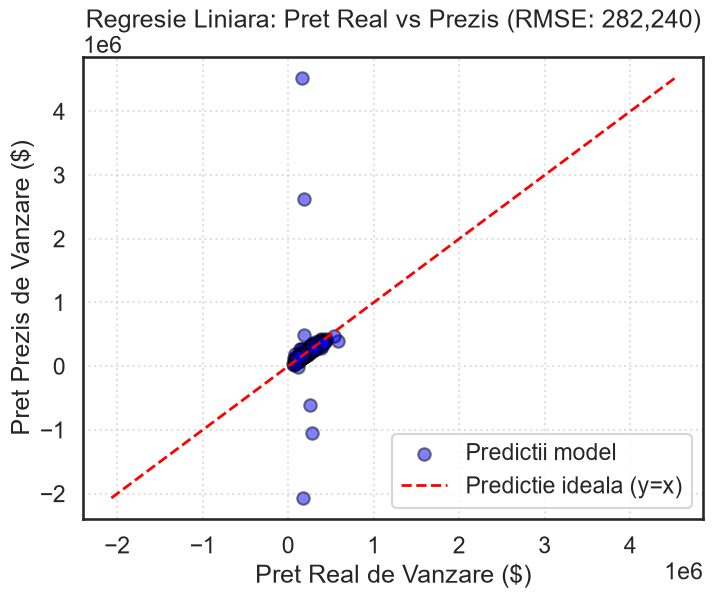

In [14]:
# Reprezentam grafic pretul de vanzare previzionat vs cel real
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred_lr, alpha=0.5, color='blue', edgecolors='k', label='Predictii model')

# Linia ideala de referinta y = x
min_val = min(y_test.min(), y_test_pred_lr.min())
max_val = max(y_test.max(), y_test_pred_lr.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predictie ideala (y=x)')

plt.xlabel('Pret Real de Vanzare ($)')
plt.ylabel('Pret Prezis de Vanzare ($)')
plt.title(f'Regresie Liniara: Pret Real vs Prezis (RMSE: {rmse_lr:,.0f})')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Întrebarea 6

Regresia Ridge utilizează normalizarea L2 pentru a reduce magnitudinea coeficienților. Acest lucru poate fi util în situații în care există o varianță ridicată. Funcțiile de regularizare din Scikit-learn conțin fiecare versiuni care au validarea încrucișată încorporată.

* Adaptați un model Ridge regulat (nevalidat încrucișat) la o gamă de valori $\alpha$ și reprezentați grafic RMSE utilizând funcția de eroare validată încrucișat pe care ați creat-o mai sus.
* Utilizați $$[0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]$$ ca interval de alphas.
* Apoi repetați ajustarea modelelor Ridge folosind gama de valori $\alpha$ din secțiunea anterioară. Comparați rezultatele.

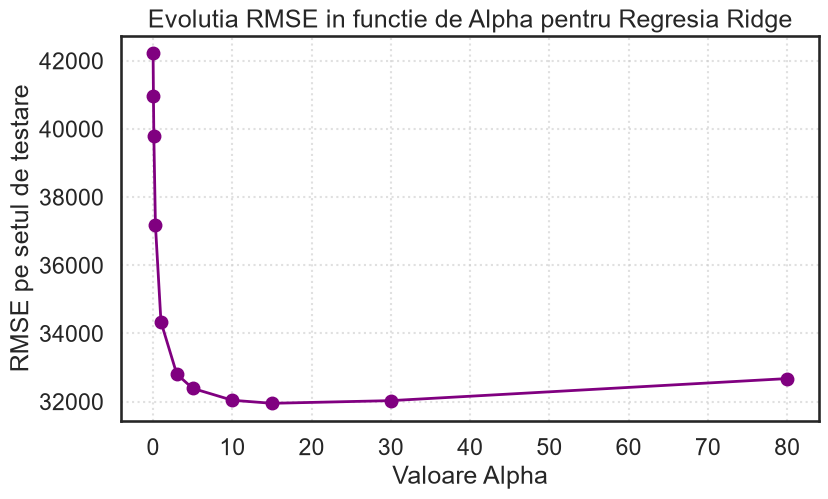

Cel mai bun alpha pentru Ridge regulat: 15 cu RMSE: 31,950.97


In [15]:
# Definim gama de valori alpha conform cerintei
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

# Calculam RMSE pe setul de test pentru fiecare alpha
rmse_regular_ridge = []
for a in alphas:
    ridge_reg = Ridge(alpha=a)
    ridge_reg.fit(X_train, y_train)
    pred = ridge_reg.predict(X_test)
    rmse_regular_ridge.append(rmse(y_test, pred))

# Reprezentam grafic evolutia RMSE in functie de alpha
plt.figure(figsize=(9, 5))
plt.plot(alphas, rmse_regular_ridge, marker='o', color='purple', linewidth=2)
plt.xlabel('Valoare Alpha')
plt.ylabel('RMSE pe setul de testare')
plt.title('Evolutia RMSE in functie de Alpha pentru Regresia Ridge')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

best_alpha_ridge = alphas[np.argmin(rmse_regular_ridge)]
print(f"Cel mai bun alpha pentru Ridge regulat: {best_alpha_ridge} cu RMSE: {min(rmse_regular_ridge):,.2f}")

Acum, pentru metoda `RidgeCV`. Din păcate, nu este posibil să obținem valorile alfa pentru modelele care nu au fost selectate. Valorile erorilor și valorile $\alpha$ rezultate sunt foarte asemănătoare cu cele obținute mai sus.

In [16]:
# Instantiem si antrenam modelul RidgeCV cu validare incrucisata (5 fold-uri)
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train, y_train)

# Predictii pe setul de testare si calculul RMSE
y_test_pred_ridge = ridge_cv.predict(X_test)
rmse_ridge = rmse(y_test, y_test_pred_ridge)

print(f"Alpha optim selectat de RidgeCV: {ridge_cv.alpha_}")
print(f"RMSE pentru RidgeCV pe setul de testare: {rmse_ridge:,.2f}")

Alpha optim selectat de RidgeCV: 10.0
RMSE pentru RidgeCV pe setul de testare: 32,040.43


## Întrebarea 7

La fel ca funcția `RidgeCV`, există și o funcție `LassoCV` care utilizează o funcție de regularizare L1 și validarea încrucișată. Regularizarea L1 va micșora selectiv anumiți coeficienți, efectuând efectiv eliminarea caracteristicilor.

Funcția `LassoCV` nu permite setarea funcției de scor. Cu toate acestea, funcția de eroare personalizată (`rmse`) creată mai sus poate fi utilizată pentru a evalua eroarea modelului final.

În mod similar, există și o funcție elastic net cu validare încrucișată, `ElasticNetCV`, care este o combinație de regularizare L2 și L1.

* Potriviți un model Lasso utilizând validarea încrucișată și determinați valoarea optimă pentru $\alpha$ și RMSE utilizând funcția creată mai sus. Rețineți că magnitudinea lui $\alpha$ poate fi diferită de cea a modelului Ridge.
* Repetați operația cu modelul de plasă elastică.
* Comparați rezultatele prin tabel și/sau grafic.

Utilizați următoarele alphas:

`[1e-5, 5e-5, 0.0001, 0.0005]`

In [17]:
# Definim lista de alphas conform cerintei
alphas_lasso = [1e-5, 5e-5, 0.0001, 0.0005]

# Instantiem si antrenam modelul LassoCV cu validare incrucisata pe 5 fold-uri
lasso_cv = LassoCV(alphas=alphas_lasso, cv=5, max_iter=5000, random_state=42)
lasso_cv.fit(X_train, y_train)

# Predictii si calcul RMSE
y_test_pred_lasso = lasso_cv.predict(X_test)
rmse_lasso = rmse(y_test, y_test_pred_lasso)

print(f"Alpha optim pentru LassoCV: {lasso_cv.alpha_}")
print(f"RMSE pentru LassoCV pe setul de testare: {rmse_lasso:,.2f}")

Alpha optim pentru LassoCV: 0.0005
RMSE pentru LassoCV pe setul de testare: 50,859.32


Putem determina câte dintre aceste caracteristici rămân diferite de zero.

In [18]:
# Numarul de caracteristici cu coeficienti diferiti de zero pentru Lasso
num_nonzero_lasso = np.sum(lasso_cv.coef_ != 0)
total_features = len(lasso_cv.coef_)

print(f"Caracteristici nenule in Lasso: {num_nonzero_lasso} din totalul de {total_features}")
print(f"Caracteristici anulate (eliminate) de Lasso: {total_features - num_nonzero_lasso}")

Caracteristici nenule in Lasso: 241 din totalul de 251
Caracteristici anulate (eliminate) de Lasso: 10


Încercați acum plasa elastică, cu aceleași alphas ca în Lasso, și l1_ratios între 0,1 și 0,9

In [19]:
# Definim grila de valori pentru l1_ratio intre 0.1 si 0.9
l1_ratios = np.linspace(0.1, 0.9, 9)

# Instantiem si antrenam modelul ElasticNetCV cu validare incrucisata
enet_cv = ElasticNetCV(alphas=alphas_lasso, l1_ratio=l1_ratios, cv=5, max_iter=5000, random_state=42)
enet_cv.fit(X_train, y_train)

# Predictii si calcul RMSE
y_test_pred_enet = enet_cv.predict(X_test)
rmse_enet = rmse(y_test, y_test_pred_enet)

print(f"Alpha optim pentru ElasticNetCV: {enet_cv.alpha_}")
print(f"l1_ratio optim pentru ElasticNetCV: {enet_cv.l1_ratio_:.2f}")
print(f"RMSE pentru ElasticNetCV: {rmse_enet:,.2f}")

num_nonzero_enet = np.sum(enet_cv.coef_ != 0)
print(f"Caracteristici nenule in ElasticNet: {num_nonzero_enet} din totalul de {total_features}")

Alpha optim pentru ElasticNetCV: 0.0005
l1_ratio optim pentru ElasticNetCV: 0.10
RMSE pentru ElasticNetCV: 36,220.50
Caracteristici nenule in ElasticNet: 241 din totalul de 251


Compararea calculului RMSE din toate modelele este cea mai ușoară într-un tabel.

In [20]:
# Cream un tabel comparativ cu performantele modelelor
rmse_table = pd.DataFrame({
    'Model': ['Linear Regression', 'RidgeCV', 'LassoCV', 'ElasticNetCV'],
    'RMSE ($)': [rmse_lr, rmse_ridge, rmse_lasso, rmse_enet]
})

print("Tabel comparativ RMSE:")
print(rmse_table.to_string(index=False))

Tabel comparativ RMSE:
            Model      RMSE ($)
Linear Regression 282240.262354
          RidgeCV  32040.433238
          LassoCV  50859.320953
     ElasticNetCV  36220.497489


Putem, de asemenea, să realizăm un grafic al prețurilor reale și previzionate ale locuințelor, la fel ca înainte.

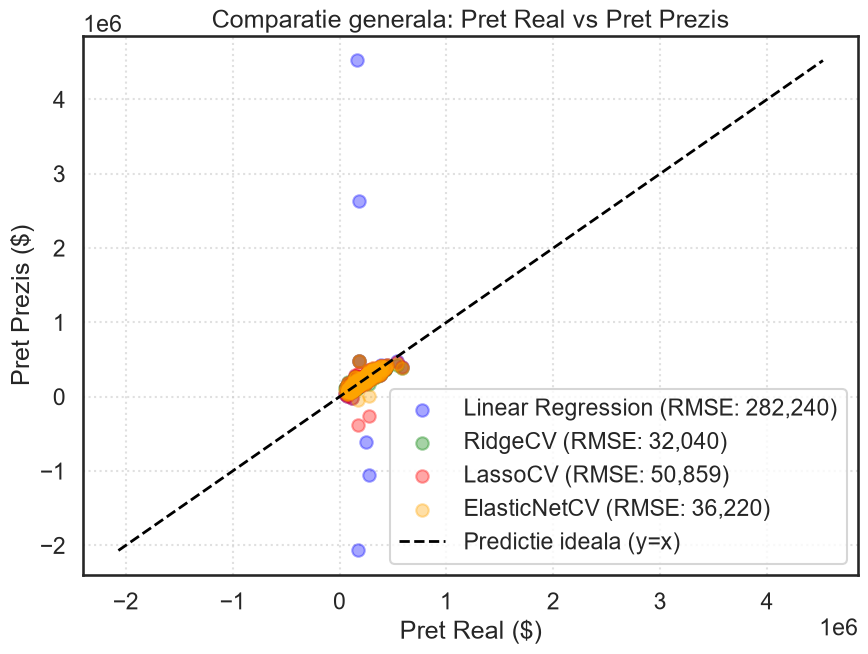

In [21]:
# Reprezentam grafic preturile reale vs previzionate pentru toate cele 4 modele
plt.figure(figsize=(10, 7))

plt.scatter(y_test, y_test_pred_lr, alpha=0.35, label=f'Linear Regression (RMSE: {rmse_lr:,.0f})', color='blue')
plt.scatter(y_test, y_test_pred_ridge, alpha=0.35, label=f'RidgeCV (RMSE: {rmse_ridge:,.0f})', color='green')
plt.scatter(y_test, y_test_pred_lasso, alpha=0.35, label=f'LassoCV (RMSE: {rmse_lasso:,.0f})', color='red')
plt.scatter(y_test, y_test_pred_enet, alpha=0.35, label=f'ElasticNetCV (RMSE: {rmse_enet:,.0f})', color='orange')

# Linia de predictie perfecta
min_val = min(y_test.min(), y_test_pred_lr.min())
max_val = max(y_test.max(), y_test_pred_lr.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='Predictie ideala (y=x)')

plt.xlabel('Pret Real ($)')
plt.ylabel('Pret Prezis ($)')
plt.title('Comparatie generala: Pret Real vs Pret Prezis')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Întrebarea 8

Să explorăm coborârea stochastică a gradientului în acest exercițiu.  
Reamintim că modelele liniare în general sunt sensibile la scalare.
Cu toate acestea, SGD este *foarte* sensibil la scalare.  
În plus, o valoare mare a ratei de învățare poate determina algoritmul să devieze, în timp ce o valoare prea mică poate dura prea mult până la convergență.

* Potriviți un model stochastic gradient descent fără o penalizare de regularizare (parametrul relevant este `penalty`).
* Ajustați acum modele stochastice de coborâre în gradient cu fiecare dintre cele trei penalizări (L2, L1, Elastic Net) folosind valorile parametrilor determinate prin validarea încrucișată de mai sus. 
* Nu scalați datele înainte de ajustarea modelului.  
* Comparați rezultatele cu cele obținute fără a utiliza coborârea stochastică în gradient.

In [22]:
# Instantiem modelele SGDRegressor fara scalare si cu rata de invatare implicita
sgd_none = SGDRegressor(penalty=None, random_state=42)
sgd_l2 = SGDRegressor(penalty='l2', alpha=ridge_cv.alpha_, random_state=42)
sgd_l1 = SGDRegressor(penalty='l1', alpha=lasso_cv.alpha_, random_state=42)
sgd_enet = SGDRegressor(penalty='elasticnet', alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, random_state=42)

sgd_models_unscaled = {
    'SGD (Fara penalizare)': sgd_none,
    'SGD (Penalizare L2)': sgd_l2,
    'SGD (Penalizare L1)': sgd_l1,
    'SGD (Penalizare ElasticNet)': sgd_enet
}

rmse_sgd_unscaled = {}
print("Rezultate SGD fara scalare (rata de invatare implicita):")
for name, model in sgd_models_unscaled.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse_val = rmse(y_test, preds)
    rmse_sgd_unscaled[name] = rmse_val
    print(f"{name:30s}: RMSE = {rmse_val:e}")

Rezultate SGD fara scalare (rata de invatare implicita):
SGD (Fara penalizare)         : RMSE = 3.893445e+15
SGD (Penalizare L2)           : RMSE = 4.949415e+15
SGD (Penalizare L1)           : RMSE = 3.893445e+15
SGD (Penalizare ElasticNet)   : RMSE = 2.829654e+15


Observați cât de mari sunt valorile erorii! Algoritmul este divergent. Acest lucru se poate datora faptului că scalarea și/sau rata de învățare sunt prea mari. Să ajustăm rata de învățare și să vedem ce se întâmplă.

* Introduceți `eta0=1e-7` la crearea instanței de `SGDRegressor`.
* Calculați din nou erorile pentru toate penalitățile și comparați.

In [23]:
# Instantiem aceleasi modele SGD cu o rata de invatare foarte mica: eta0=1e-7
sgd_none_eta = SGDRegressor(penalty=None, eta0=1e-7, learning_rate='constant', random_state=42)
sgd_l2_eta = SGDRegressor(penalty='l2', alpha=ridge_cv.alpha_, eta0=1e-7, learning_rate='constant', random_state=42)
sgd_l1_eta = SGDRegressor(penalty='l1', alpha=lasso_cv.alpha_, eta0=1e-7, learning_rate='constant', random_state=42)
sgd_enet_eta = SGDRegressor(penalty='elasticnet', alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, eta0=1e-7, learning_rate='constant', random_state=42)

sgd_models_eta = {
    'SGD (Fara penalizare, eta0=1e-7)': sgd_none_eta,
    'SGD (Penalizare L2, eta0=1e-7)': sgd_l2_eta,
    'SGD (Penalizare L1, eta0=1e-7)': sgd_l1_eta,
    'SGD (Penalizare ElasticNet, eta0=1e-7)': sgd_enet_eta
}

rmse_sgd_eta = {}
print("Rezultate SGD cu eta0=1e-7 (fara scalare):")
for name, model in sgd_models_eta.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse_val = rmse(y_test, preds)
    rmse_sgd_eta[name] = rmse_val
    print(f"{name:40s}: RMSE = {rmse_val:,.2f}")

Rezultate SGD cu eta0=1e-7 (fara scalare):
SGD (Fara penalizare, eta0=1e-7)        : RMSE = 96,438.32
SGD (Penalizare L2, eta0=1e-7)          : RMSE = 96,573.47
SGD (Penalizare L1, eta0=1e-7)          : RMSE = 96,438.32
SGD (Penalizare ElasticNet, eta0=1e-7)  : RMSE = 96,438.33


Acum să ne scalăm datele de antrenament și să încercăm din nou.

* Adaptați un `MinMaxScaler` la `X_train` și creați o variabilă `X_train_scaled`.
* Folosind scala, transformați `X_test` și creați o variabilă `X_test_scaled`. 
* Aplicați-le aceleași versiuni ale SGD și comparați rezultatele. De data aceasta nu introduceți un eta0.

In [24]:
# Scalam datele folosind MinMaxScaler conform cerintei
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Antrenam aceleasi versiuni de SGD pe datele scalate, cu rate de invatare implicite (fara eta0 manual)
sgd_none_scaled = SGDRegressor(penalty=None, random_state=42)
sgd_l2_scaled = SGDRegressor(penalty='l2', alpha=ridge_cv.alpha_, random_state=42)
sgd_l1_scaled = SGDRegressor(penalty='l1', alpha=lasso_cv.alpha_, random_state=42)
sgd_enet_scaled = SGDRegressor(penalty='elasticnet', alpha=enet_cv.alpha_, l1_ratio=enet_cv.l1_ratio_, random_state=42)

sgd_models_scaled = {
    'SGD Scalat (Fara penalizare)': sgd_none_scaled,
    'SGD Scalat (Penalizare L2)': sgd_l2_scaled,
    'SGD Scalat (Penalizare L1)': sgd_l1_scaled,
    'SGD Scalat (Penalizare ElasticNet)': sgd_enet_scaled
}

rmse_sgd_scaled = {}
print("Rezultate SGD dupa scalarea datelor cu MinMaxScaler (rata implicita):")
for name, model in sgd_models_scaled.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    rmse_val = rmse(y_test, preds)
    rmse_sgd_scaled[name] = rmse_val
    print(f"{name:35s}: RMSE = {rmse_val:,.2f}")

Rezultate SGD dupa scalarea datelor cu MinMaxScaler (rata implicita):
SGD Scalat (Fara penalizare)       : RMSE = 32,671.88
SGD Scalat (Penalizare L2)         : RMSE = 70,585.54
SGD Scalat (Penalizare L1)         : RMSE = 32,671.87
SGD Scalat (Penalizare ElasticNet) : RMSE = 32,639.46


In [25]:
# Tabel recapitulativ final al performantelor SGD
comparison_sgd = pd.DataFrame({
    'Model': list(rmse_sgd_unscaled.keys()),
    'RMSE Nescalat (implicit)': [f"{v:e}" for v in rmse_sgd_unscaled.values()],
    'RMSE Nescalat (eta0=1e-7)': [f"{v:,.2f}" for v in rmse_sgd_eta.values()],
    'RMSE Scalat MinMaxScaler': [f"{v:,.2f}" for v in rmse_sgd_scaled.values()]
})

print("Tabel comparativ final pentru SGD:")
print(comparison_sgd.to_string(index=False))

Tabel comparativ final pentru SGD:
                      Model RMSE Nescalat (implicit) RMSE Nescalat (eta0=1e-7) RMSE Scalat MinMaxScaler
      SGD (Fara penalizare)             3.893445e+15                 96,438.32                32,671.88
        SGD (Penalizare L2)             4.949415e+15                 96,573.47                70,585.54
        SGD (Penalizare L1)             3.893445e+15                 96,438.32                32,671.87
SGD (Penalizare ElasticNet)             2.829654e+15                 96,438.33                32,639.46


### Concluzii privind Coborârea Stochastică a Gradientului (SGD):

1. **Sensibilitatea critică la scalare**: Algoritmii de gradient calculează derivatele parțiale ale funcției de cost în raport cu ponderile. Dacă datele nu sunt scalate (valori de la $0$ la mii), gradienții iau valori enorme, iar pașii de actualizare provoacă **divergența algoritmului** (erori de ordinul $10^{15}$).
2. **Rolul ratei de învățare (`eta0`)**: Micșorarea ratei de învățare (ex: `eta0=1e-7`) permite algoritmului să nu devieze chiar și fără scalare, dar pașii sunt foarte mici și convergența poate fi lentă.
3. **Scalarea caracteristicilor (`MinMaxScaler`)**: Aduce toate caracteristicile în intervalul $[0, 1]$, ceea ce permite utilizarea ratei de învățare implicite cu o convergență rapidă și stabilă, obținând performanțe competitive (RMSE $\approx 32.000 - 36.000$) similare regresiei liniare analitice.